In [1]:
from statsbombpy import sb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch
import warnings
warnings.filterwarnings('ignore')

In [2]:
comps = sb.competitions()
comps[['competition_id', 'competition_name', 'season_id', 'season_name']].head(30)

,competition_id,competition_name,season_id,season_name
0,9,1. Bundesliga,281,2023/2024
1,9,1. Bundesliga,27,2015/2016
2,1267,African Cup of Nations,107,2023
3,16,Champions League,4,2018/2019
4,16,Champions League,1,2017/2018
5,16,Champions League,2,2016/2017
6,16,Champions League,27,2015/2016
7,16,Champions League,26,2014/2015
8,16,Champions League,25,2013/2014
9,16,Champions League,24,2012/2013


In [3]:
# La Liga 2020/2021
matches = sb.matches(competition_id=11, season_id=90)
print(f"{len(matches)} matchs disponibles")
matches[['match_id', 'home_team', 'away_team', 'home_score', 'away_score']].head(10)

35 matchs disponibles


,match_id,home_team,away_team,home_score,away_score
0,3773386,Deportivo Alavés,Barcelona,1,1
1,3773565,Granada,Barcelona,0,4
2,3773457,Barcelona,Celta Vigo,1,2
3,3773631,Real Betis,Barcelona,2,3
4,3773665,Osasuna,Barcelona,0,2
5,3773497,Real Madrid,Barcelona,2,1
6,3773660,Barcelona,Levante UD,1,0
7,3773593,Barcelona,Villarreal,4,0
8,3773466,Celta Vigo,Barcelona,0,3
9,3773585,Barcelona,Real Madrid,1,3


In [4]:
# Prends le premier match pour explorer
match_id = matches.iloc[0]['match_id']
events = sb.events(match_id=match_id)

# Regarde les types d'événements
print(events['type'].value_counts())

type
Pass                 1118
Ball Receipt*        1059
Carry                 888
Pressure              307
Ball Recovery          99
Duel                   63
Dribble                40
Block                  39
Clearance              39
Goal Keeper            35
Dispossessed           29
Shot                   29
Dribbled Past          26
Miscontrol             26
Foul Committed         26
Foul Won               26
Interception           14
Substitution           10
Half Start              4
Half End                4
Starting XI             2
Referee Ball-Drop       2
50/50                   2
Error                   1
Injury Stoppage         1
Bad Behaviour           1
Tactical Shift          1
Name: count, dtype: int64


In [5]:
shots = events[events['type'] == 'Shot']
print(f"{len(shots)} tirs dans ce match")

# Affiche un tir en détail
shots.iloc[0][['player', 'location', 'shot_statsbomb_xg', 
               'shot_outcome', 'shot_body_part', 'shot_type',
               'shot_technique', 'shot_end_location',
               'shot_first_time', 'shot_one_on_one',
               'under_pressure', 'play_pattern']]

29 tirs dans ce match


player                   Anssumane Fati
location                  [108.6, 28.0]
shot_statsbomb_xg              0.200969
shot_outcome                      Off T
shot_body_part               Right Foot
shot_type                     Open Play
shot_technique                   Normal
shot_end_location    [120.0, 47.8, 0.0]
shot_first_time                     NaN
shot_one_on_one                    True
under_pressure                      NaN
play_pattern              From Throw In
Name: 3805, dtype: object

In [6]:
competitions_to_use = [
    (11, 90, "La Liga 2020/2021"),
    (11, 42, "La Liga 2019/2020"),
    (11, 4, "La Liga 2018/2019"),
    (2, 27, "Premier League 2015/2016"),
    (7, 235, "Ligue 1 2022/2023"),
    (7, 108, "Ligue 1 2021/2022"),
    (9, 281, "Bundesliga 2023/2024"),
    (55, 282, "Euro 2024"),
]

all_shots = []

for comp_id, season_id, label in competitions_to_use:
    print(f"Loading {label}...", end=" ")
    try:
        matches = sb.matches(competition_id=comp_id, season_id=season_id)
        comp_shots = []
        for mid in matches['match_id']:
            try:
                events = sb.events(match_id=mid)
                shots = events[events['type'] == 'Shot'].copy()
                shots['competition'] = label
                comp_shots.append(shots)
            except:
                continue
        df = pd.concat(comp_shots, ignore_index=True)
        all_shots.append(df)
        print(f"{len(df)} tirs")
    except Exception as e:
        print(f"Erreur: {e}")

shots_df = pd.concat(all_shots, ignore_index=True)
print(f"\nTotal : {len(shots_df)} tirs collectés")

Loading La Liga 2020/2021... 839 tirs
Loading La Liga 2019/2020... 752 tirs
Loading La Liga 2018/2019... 887 tirs
Loading Premier League 2015/2016... 9908 tirs
Loading Ligue 1 2022/2023... 851 tirs
Loading Ligue 1 2021/2022... 681 tirs
Loading Bundesliga 2023/2024... 916 tirs
Loading Euro 2024... 1340 tirs

Total : 16174 tirs collectés


In [7]:
print(f"Tirs par compétition :")
print(shots_df['competition'].value_counts())
print(f"\nRésultats des tirs :")
print(shots_df['shot_outcome'].value_counts())
print(f"\nTaux de conversion : {(shots_df['shot_outcome'] == 'Goal').mean()*100:.1f}%")

Tirs par compétition :
competition
Premier League 2015/2016    9908
Euro 2024                   1340
Bundesliga 2023/2024         916
La Liga 2018/2019            887
Ligue 1 2022/2023            851
La Liga 2020/2021            839
La Liga 2019/2020            752
Ligue 1 2021/2022            681
Name: count, dtype: int64

Résultats des tirs :
shot_outcome
Off T               5050
Blocked             4479
Saved               3808
Goal                1735
Wayward              681
Post                 307
Saved Off Target      71
Saved to Post         43
Name: count, dtype: int64

Taux de conversion : 10.7%


In [8]:
# Le terrain StatsBomb fait 120x80 yards
# Le but est à x=120, centré à y=40
# Les poteaux sont à y=36 et y=44

shots_df['x'] = shots_df['location'].apply(lambda loc: loc[0])
shots_df['y'] = shots_df['location'].apply(lambda loc: loc[1])

print(f"x : min={shots_df['x'].min():.1f}, max={shots_df['x'].max():.1f}")
print(f"y : min={shots_df['y'].min():.1f}, max={shots_df['y'].max():.1f}")

x : min=35.4, max=120.2
y : min=0.8, max=79.3


In [9]:
goal_x, goal_y = 120, 40

# Distance au centre du but
shots_df['distance'] = np.sqrt(
    (goal_x - shots_df['x'])**2 + (goal_y - shots_df['y'])**2
)

# Angle de tir (angle sous-tendu entre les deux poteaux)
def calc_angle(row):
    shot = np.array([row['x'], row['y']])
    post_left = np.array([120, 36])
    post_right = np.array([120, 44])
    
    v1 = post_left - shot
    v2 = post_right - shot
    
    cos_angle = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-6)
    return np.degrees(np.arccos(np.clip(cos_angle, -1, 1)))

shots_df['angle'] = shots_df.apply(calc_angle, axis=1)

print(f"Distance : moy={shots_df['distance'].mean():.1f}, med={shots_df['distance'].median():.1f}")
print(f"Angle : moy={shots_df['angle'].mean():.1f}°, med={shots_df['angle'].median():.1f}°")

Distance : moy=18.8, med=18.3
Angle : moy=25.4°, med=19.9°


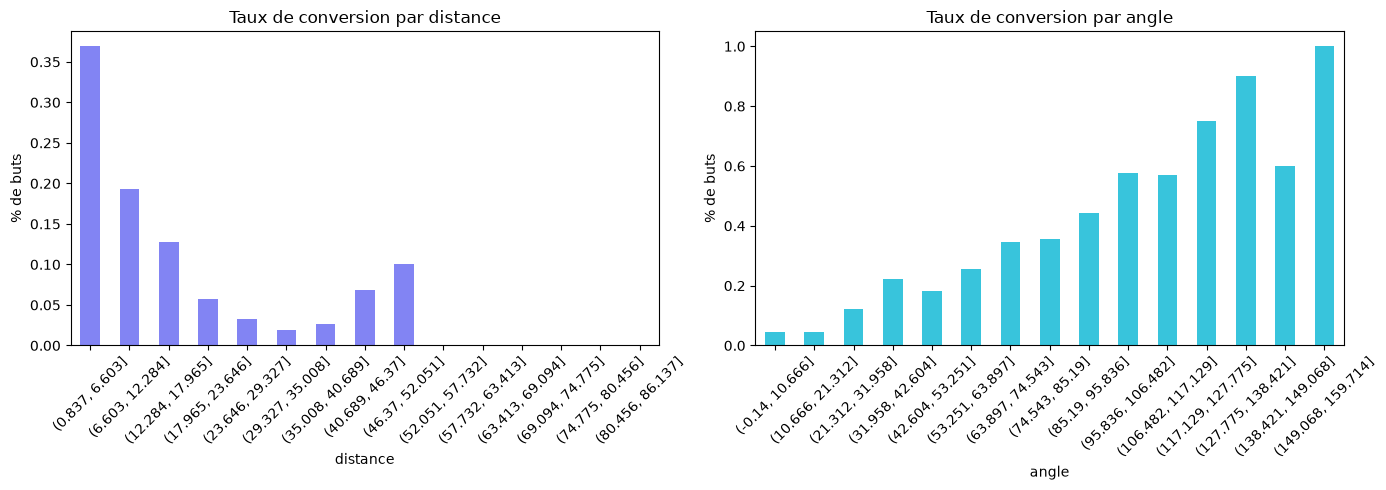

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

shots_df['is_goal'] = (shots_df['shot_outcome'] == 'Goal').astype(int)

# Distance vs taux de conversion
bins = pd.cut(shots_df['distance'], bins=15)
conv_by_dist = shots_df.groupby(bins)['is_goal'].mean()
conv_by_dist.plot(kind='bar', ax=axes[0], color='#6366f1', alpha=0.8)
axes[0].set_title('Taux de conversion par distance')
axes[0].set_ylabel('% de buts')
axes[0].tick_params(axis='x', rotation=45)

# Angle vs taux de conversion
bins_angle = pd.cut(shots_df['angle'], bins=15)
conv_by_angle = shots_df.groupby(bins_angle)['is_goal'].mean()
conv_by_angle.plot(kind='bar', ax=axes[1], color='#06b6d4', alpha=0.8)
axes[1].set_title('Taux de conversion par angle')
axes[1].set_ylabel('% de buts')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [11]:
# Partie du corps
shots_df['is_head'] = (shots_df['shot_body_part'] == 'Head').astype(int)
shots_df['is_right_foot'] = (shots_df['shot_body_part'] == 'Right Foot').astype(int)
shots_df['is_left_foot'] = (shots_df['shot_body_part'] == 'Left Foot').astype(int)

# Type de tir
shots_df['is_open_play'] = (shots_df['shot_type'] == 'Open Play').astype(int)
shots_df['is_free_kick'] = (shots_df['shot_type'] == 'Free Kick').astype(int)
shots_df['is_penalty'] = (shots_df['shot_type'] == 'Penalty').astype(int)

# Contexte tactique
shots_df['is_counter'] = (shots_df['play_pattern'] == 'From Counter').astype(int)
shots_df['is_set_piece'] = shots_df['play_pattern'].isin(
    ['From Corner', 'From Free Kick', 'From Throw In']
).astype(int)

# Situations de jeu
shots_df['is_first_time'] = shots_df['shot_first_time'].fillna(False).astype(int)
shots_df['follows_dribble'] = shots_df['shot_follows_dribble'].fillna(False).astype(int)
shots_df['is_one_on_one'] = shots_df['shot_one_on_one'].fillna(False).astype(int)
shots_df['under_pressure'] = shots_df['under_pressure'].fillna(False).astype(int)
shots_df['is_open_goal'] = shots_df['shot_open_goal'].fillna(False).astype(int)

# Technique de tir
shots_df['is_volley'] = (shots_df['shot_technique'] == 'Volley').astype(int)
shots_df['is_half_volley'] = (shots_df['shot_technique'] == 'Half Volley').astype(int)
shots_df['is_lob'] = (shots_df['shot_technique'] == 'Lob').astype(int)

# xG StatsBomb pour comparaison
shots_df['sb_xg'] = shots_df['shot_statsbomb_xg'].astype(float)

print("Features créées :")
feature_cols = ['distance', 'angle', 'is_head', 'is_right_foot', 'is_left_foot',
                'is_open_play', 'is_free_kick', 'is_counter', 'is_set_piece',
                'is_first_time', 'follows_dribble', 'is_one_on_one',
                'under_pressure', 'is_open_goal', 'is_volley', 'is_half_volley',
                'is_lob', 'x', 'y']
print(f"{len(feature_cols)} features")
print(shots_df[feature_cols].describe().round(2))

Features créées :
19 features
       distance     angle   is_head  is_right_foot  is_left_foot  \
count  16174.00  16174.00  16174.00       16174.00      16174.00   
mean      18.82     25.43      0.15           0.52          0.33   
std        8.26     15.39      0.36           0.50          0.47   
min        0.92      0.02      0.00           0.00          0.00   
25%       12.07     15.51      0.00           0.00          0.00   
50%       18.34     19.91      0.00           1.00          0.00   
75%       24.83     30.79      0.00           1.00          1.00   
max       86.14    159.71      1.00           1.00          1.00   

       is_open_play  is_free_kick  is_counter  is_set_piece  is_first_time  \
count      16174.00      16174.00    16174.00      16174.00       16174.00   
mean           0.94          0.04        0.05          0.52           0.30   
std            0.23          0.21        0.21          0.50           0.46   
min            0.00          0.00        0.00

In [12]:
from sklearn.model_selection import train_test_split

# Retirer les penalties
shots_no_pen = shots_df[shots_df['is_penalty'] == 0].copy()
print(f"Tirs sans penalties : {len(shots_no_pen)}")
print(f"Buts : {shots_no_pen['is_goal'].sum()} ({shots_no_pen['is_goal'].mean()*100:.1f}%)")

# Features et target
features = ['distance', 'angle', 'is_head', 'is_right_foot', 'is_left_foot',
            'is_open_play', 'is_free_kick', 'is_counter', 'is_set_piece',
            'is_first_time', 'follows_dribble', 'is_one_on_one',
            'under_pressure', 'is_open_goal', 'is_volley', 'is_half_volley',
            'is_lob', 'x', 'y']

X = shots_no_pen[features].fillna(0)
y = shots_no_pen['is_goal']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"\nTrain : {len(X_train)} tirs")
print(f"Test  : {len(X_test)} tirs")
print(f"Ratio de buts (train) : {y_train.mean()*100:.1f}%")
print(f"Ratio de buts (test)  : {y_test.mean()*100:.1f}%")

Tirs sans penalties : 15986
Buts : 1583 (9.9%)

Train : 11989 tirs
Test  : 3997 tirs
Ratio de buts (train) : 9.9%
Ratio de buts (test)  : 9.9%


In [13]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

# Les coefficients nous disent l'effet de chaque feature
coefs = pd.Series(lr.coef_[0], index=features).sort_values()
print("Coefficients du modèle :")
for feat, coef in coefs.items():
    direction = "+" if coef > 0 else "-"
    print(f"  {direction} {feat:25s} {coef:+.4f}")

Coefficients du modèle :
  - follows_dribble           -0.5870
  - is_volley                 -0.5756
  - is_half_volley            -0.4733
  - is_head                   -0.3807
  - under_pressure            -0.2295
  - distance                  -0.1463
  - is_set_piece              -0.0845
  - x                         -0.0388
  - y                         -0.0046
  + angle                     +0.0200
  + is_first_time             +0.1255
  + is_counter                +0.3351
  + is_open_play              +0.4901
  + is_one_on_one             +0.7117
  + is_open_goal              +0.9149
  + is_left_foot              +0.9845
  + is_right_foot             +0.9853
  + is_lob                    +1.3226
  + is_free_kick              +1.3867


In [14]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.1,
    subsample=0.8, random_state=42
)
gb.fit(X_train, y_train)

print("Gradient Boosting entraîné")

Gradient Boosting entraîné


In [15]:
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

# Prédictions
lr_probs = lr.predict_proba(X_test)[:, 1]
gb_probs = gb.predict_proba(X_test)[:, 1]
sb_xg_test = shots_no_pen.loc[X_test.index, 'sb_xg'].values

print("=" * 55)
print(f"{'Modèle':<30} {'ROC AUC':>8} {'Brier':>8} {'LogLoss':>8}")
print("=" * 55)

for name, probs in [("Logistic Regression", lr_probs),
                     ("Gradient Boosting", gb_probs),
                     ("StatsBomb xG (référence)", sb_xg_test)]:
    auc = roc_auc_score(y_test, probs)
    brier = brier_score_loss(y_test, probs)
    ll = log_loss(y_test, probs)
    print(f"{name:<30} {auc:>8.4f} {brier:>8.4f} {ll:>8.4f}")

Modèle                          ROC AUC    Brier  LogLoss
Logistic Regression              0.7895   0.0778   0.2722
Gradient Boosting                0.7716   0.0828   0.2852
StatsBomb xG (référence)         0.8007   0.0749   0.2639


In [16]:
importances = pd.Series(gb.feature_importances_, index=features).sort_values(ascending=False)
print("Top 10 features :")
for feat, imp in importances.head(10).items():
    print(f"  {feat:25s} {imp*100:.1f}%")

Top 10 features :
  angle                     35.7%
  distance                  21.7%
  y                         10.1%
  x                         8.0%
  is_head                   6.8%
  is_open_goal              4.7%
  is_one_on_one             2.7%
  under_pressure            1.4%
  is_half_volley            1.4%
  is_lob                    1.2%


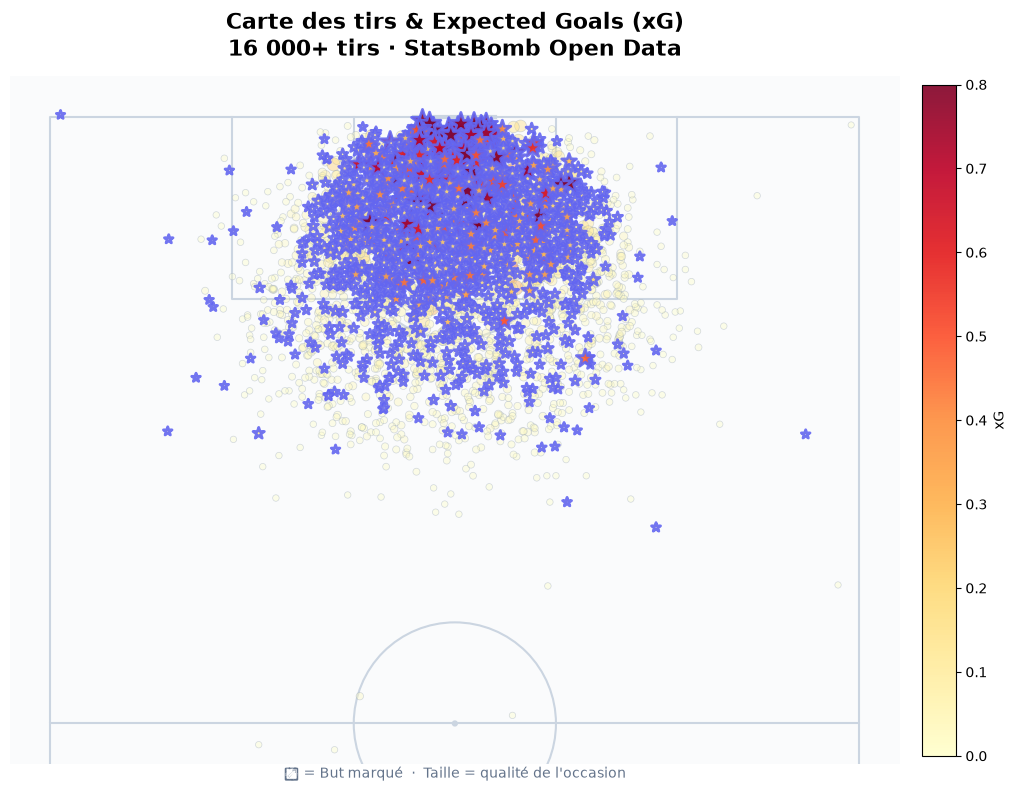

In [17]:
from mplsoccer import VerticalPitch

fig, ax = plt.subplots(figsize=(12, 8))

pitch = VerticalPitch(
    pitch_type='statsbomb', half=True,
    pitch_color='#FAFBFC', line_color='#cbd5e1', linewidth=1.5
)
pitch.draw(ax=ax)

# Séparer buts et non-buts
goals = shots_no_pen[shots_no_pen['is_goal'] == 1]
misses = shots_no_pen[shots_no_pen['is_goal'] == 0].sample(2000, random_state=42)

# Non-buts (petits, transparents)
pitch.scatter(misses['x'], misses['y'], ax=ax,
              s=misses['sb_xg']*300 + 20,
              c=misses['sb_xg'], cmap='YlOrRd',
              edgecolors='#94a3b8', linewidth=0.5,
              alpha=0.4, zorder=2, vmin=0, vmax=0.8)

# Buts (étoiles, bien visibles)
sc = pitch.scatter(goals['x'], goals['y'], ax=ax,
                   s=goals['sb_xg']*300 + 40,
                   c=goals['sb_xg'], cmap='YlOrRd',
                   edgecolors='#6366f1', linewidth=2,
                   alpha=0.9, zorder=3, vmin=0, vmax=0.8,
                   marker='*')

plt.colorbar(sc, ax=ax, fraction=0.03, pad=0.02, label='xG')

ax.set_title('Carte des tirs & Expected Goals (xG)\n16 000+ tirs · StatsBomb Open Data',
             fontsize=16, fontweight='bold', pad=15)
ax.text(0.5, -0.02, '⭐ = But marqué  ·  Taille = qualité de l\'occasion',
        transform=ax.transAxes, ha='center', fontsize=10, color='#64748b')

plt.tight_layout()
plt.savefig('shot_map.png', dpi=150, bbox_inches='tight', facecolor='#FAFBFC')
plt.show()

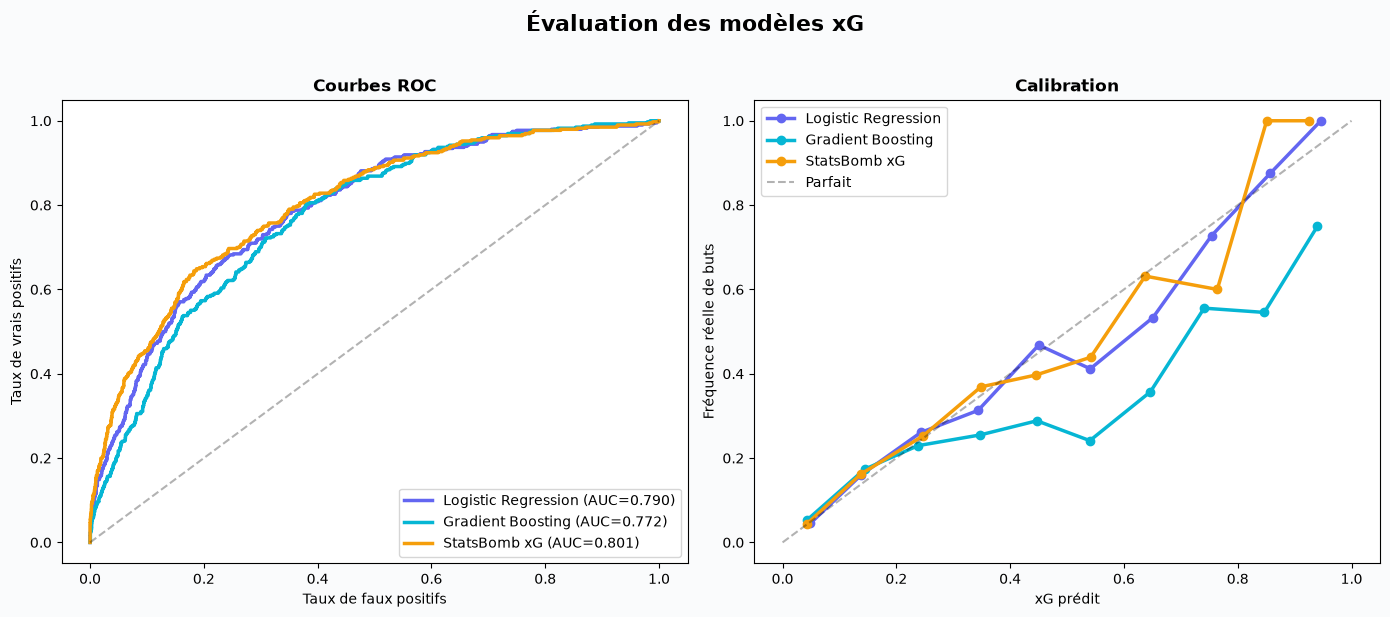

In [18]:
from sklearn.metrics import roc_curve
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6), facecolor='#FAFBFC')

models = [
    ('Logistic Regression', lr_probs, '#6366f1'),
    ('Gradient Boosting', gb_probs, '#06b6d4'),
    ('StatsBomb xG', sb_xg_test, '#f59e0b'),
]

# ROC
for name, probs, color in models:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    axes[0].plot(fpr, tpr, color=color, linewidth=2.5,
                 label=f'{name} (AUC={auc:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[0].set_xlabel('Taux de faux positifs')
axes[0].set_ylabel('Taux de vrais positifs')
axes[0].set_title('Courbes ROC', fontweight='bold')
axes[0].legend(loc='lower right')

# Calibration
for name, probs, color in models:
    prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10)
    axes[1].plot(prob_pred, prob_true, marker='o', color=color,
                 linewidth=2.5, markersize=6, label=name)

axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Parfait')
axes[1].set_xlabel('xG prédit')
axes[1].set_ylabel('Fréquence réelle de buts')
axes[1].set_title('Calibration', fontweight='bold')
axes[1].legend(loc='upper left')

plt.suptitle('Évaluation des modèles xG', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('model_evaluation.png', dpi=150, bbox_inches='tight', facecolor='#FAFBFC')
plt.show()

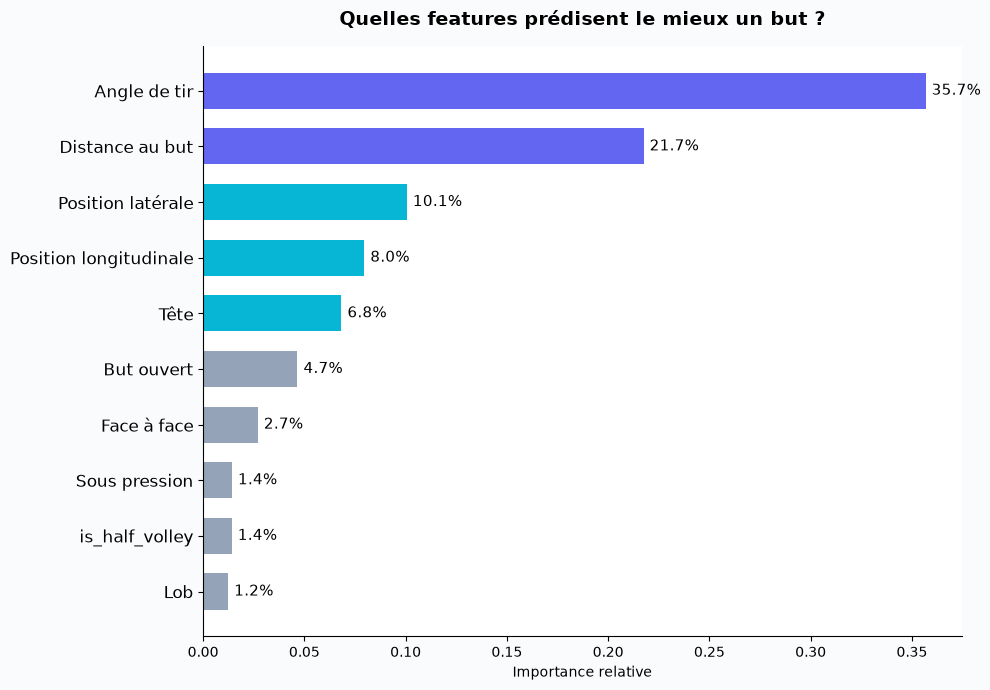

In [19]:
fig, ax = plt.subplots(figsize=(10, 7), facecolor='#FAFBFC')

labels_fr = {
    'angle': 'Angle de tir', 'distance': 'Distance au but',
    'y': 'Position latérale', 'x': 'Position longitudinale',
    'is_open_goal': 'But ouvert', 'is_head': 'Tête',
    'is_one_on_one': 'Face à face', 'under_pressure': 'Sous pression',
    'is_set_piece': 'Coup de pied arrêté', 'is_lob': 'Lob',
    'is_first_time': 'Première intention', 'follows_dribble': 'Après dribble',
}

top = importances.head(10)
labels = [labels_fr.get(f, f) for f in top.index]
values = top.values
colors = ['#6366f1' if i < 2 else '#06b6d4' if i < 5 else '#94a3b8'
          for i in range(len(values))]

bars = ax.barh(range(len(values)), values, color=colors, height=0.65)
ax.set_yticks(range(len(values)))
ax.set_yticklabels(labels, fontsize=12)
ax.invert_yaxis()
ax.set_xlabel('Importance relative')
ax.set_title('Quelles features prédisent le mieux un but ?',
             fontsize=14, fontweight='bold', pad=15)

for i, v in enumerate(values):
    ax.text(v + 0.003, i, f'{v*100:.1f}%', va='center', fontsize=11)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight', facecolor='#FAFBFC')
plt.show()

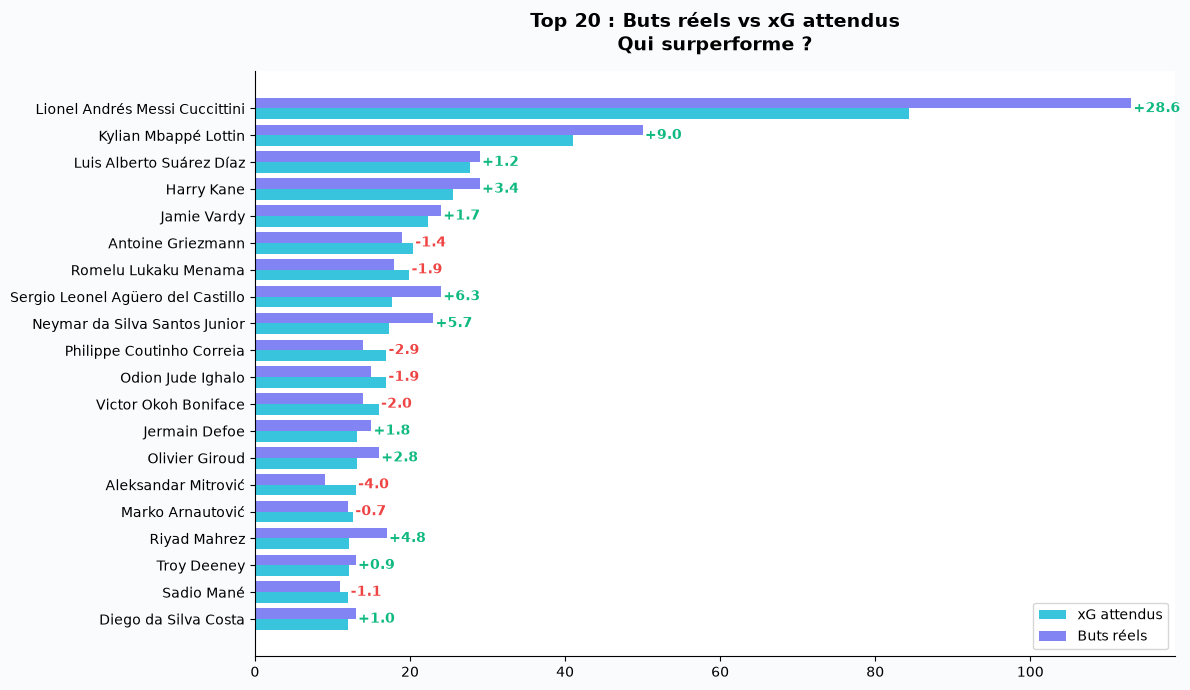

In [20]:
player_stats = shots_df.groupby('player').agg(
    tirs=('is_goal', 'count'),
    buts=('is_goal', 'sum'),
    xg_total=('sb_xg', 'sum'),
).reset_index()
player_stats['diff'] = player_stats['buts'] - player_stats['xg_total']
player_stats = player_stats[player_stats['tirs'] >= 30].sort_values('xg_total', ascending=False)

fig, ax = plt.subplots(figsize=(12, 7), facecolor='#FAFBFC')

top20 = player_stats.head(20).sort_values('xg_total', ascending=True)
y_pos = range(len(top20))

ax.barh(y_pos, top20['xg_total'], height=0.4, color='#06b6d4',
        alpha=0.8, label='xG attendus')
ax.barh([y + 0.4 for y in y_pos], top20['buts'], height=0.4,
        color='#6366f1', alpha=0.8, label='Buts réels')

ax.set_yticks([y + 0.2 for y in y_pos])
ax.set_yticklabels(top20['player'], fontsize=10)
ax.set_title('Top 20 : Buts réels vs xG attendus\nQui surperforme ?',
             fontsize=14, fontweight='bold', pad=15)
ax.legend(loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for i, (_, row) in enumerate(top20.iterrows()):
    diff = row['diff']
    color = '#10b981' if diff > 0 else '#ef4444'
    sign = '+' if diff > 0 else ''
    ax.text(max(row['buts'], row['xg_total']) + 0.3, i + 0.2,
            f'{sign}{diff:.1f}', color=color, fontweight='bold', va='center')

plt.tight_layout()
plt.savefig('players_xg.png', dpi=150, bbox_inches='tight', facecolor='#FAFBFC')
plt.show()